In [32]:
import os
import json
import xml.etree.ElementTree as ET
from pathlib import Path
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt

In [ ]:
# Crando el dataset de xml a json

def parse_xml_file(filepath):
    tree = ET.parse(filepath)
    root = tree.getroot()
    
    record = {
        "id": root.get("id"),
        "topic_id": root.get("topic_id"),
        "stance": root.get("stance"),
        "edus": [],
        "adus": [],
        "edges": []
    }
    
    for edu in root.findall("edu"):
        record["edus"].append({
            "id": edu.get("id"),
            "text": edu.text.strip() if edu.text else ""
        })
    
    for adu in root.findall("adu"):
        record["adus"].append({
            "id": adu.get("id"),
            "type": adu.get("type")
        })
    
    for edge in root.findall("edge"):
        record["edges"].append({
            "id": edge.get("id"),
            "src": edge.get("src"),
            "trg": edge.get("trg"),
            "type": edge.get("type")
        })
    
    return record

def build_dataset(folder_path, output_file="dataset.json"):
    folder = Path(folder_path)
    xml_files = sorted(folder.glob("*.xml"))
    
    if not xml_files:
        print(f"No se encontraron archivos .xml en: {folder_path}")
        return
    
    dataset = {}
    
    for xml_file in xml_files:
        file_id = xml_file.stem          # nombre sin extensión, ej: "micro_b002"
        print(f"Procesando: {xml_file.name}")
        
        try:
            record = parse_xml_file(xml_file)
            record["file_id"] = file_id  # identificador basado en nombre de archivo
            dataset[file_id] = record
        except ET.ParseError as e:
            print(f"  ⚠ Error al parsear {xml_file.name}: {e}")
    
    with open(output_file, "w", encoding="utf-8") as f:
        json.dump(dataset, f, ensure_ascii=False, indent=2)
    
    print(f"\n✓ Dataset generado: {output_file} ({len(dataset)} archivos procesados)")
    return dataset

PATH = "./dataset_microtexts/"
FOLDER = PATH + "en"
OUTPUT = PATH + "microtexts.json"

# build_dataset(FOLDER, OUTPUT)

Procesando: micro_b001.xml
Procesando: micro_b002.xml
Procesando: micro_b003.xml
Procesando: micro_b004.xml
Procesando: micro_b005.xml
Procesando: micro_b006.xml
Procesando: micro_b007.xml
Procesando: micro_b008.xml
Procesando: micro_b009.xml
Procesando: micro_b010.xml
Procesando: micro_b011.xml
Procesando: micro_b012.xml
Procesando: micro_b013.xml
Procesando: micro_b014.xml
Procesando: micro_b015.xml
Procesando: micro_b016.xml
Procesando: micro_b017.xml
Procesando: micro_b018.xml
Procesando: micro_b019.xml
Procesando: micro_b020.xml
Procesando: micro_b021.xml
Procesando: micro_b022.xml
Procesando: micro_b023.xml
Procesando: micro_b024.xml
Procesando: micro_b025.xml
Procesando: micro_b026.xml
Procesando: micro_b027.xml
Procesando: micro_b028.xml
Procesando: micro_b029.xml
Procesando: micro_b030.xml
Procesando: micro_b031.xml
Procesando: micro_b032.xml
Procesando: micro_b033.xml
Procesando: micro_b034.xml
Procesando: micro_b035.xml
Procesando: micro_b036.xml
Procesando: micro_b037.xml
P

{'micro_b001': {'id': 'micro_b001',
  'topic_id': 'waste_separation',
  'stance': 'pro',
  'edus': [{'id': 'e1',
    'text': "Yes, it's annoying and cumbersome to separate your rubbish properly all the time."},
   {'id': 'e2',
    'text': 'Three different bin bags stink away in the kitchen and have to be sorted into different wheelie bins.'},
   {'id': 'e3', 'text': 'But still Germany produces way too much rubbish'},
   {'id': 'e4',
    'text': 'and too many resources are lost when what actually should be separated and recycled is burnt.'},
   {'id': 'e5',
    'text': 'We Berliners should take the chance and become pioneers in waste separation!'}],
  'adus': [{'id': 'a1', 'type': 'opp'},
   {'id': 'a2', 'type': 'opp'},
   {'id': 'a3', 'type': 'pro'},
   {'id': 'a4', 'type': 'pro'},
   {'id': 'a5', 'type': 'pro'}],
  'edges': [{'id': 'c6', 'src': 'e1', 'trg': 'a1', 'type': 'seg'},
   {'id': 'c7', 'src': 'e2', 'trg': 'a2', 'type': 'seg'},
   {'id': 'c8', 'src': 'e3', 'trg': 'a3', 'type':

In [16]:
# Cargar el CSV e filtrar solo por el dataset Microtext
df = pd.read_csv("./dataset_aries/data.csv")
# Clean data
df["proposition_1"] = df["proposition_1"].str.strip() 
df["proposition_2"] = df["proposition_2"].str.strip()

In [73]:
columna = "data_source"
df_microtext = df[df[columna] == "Microtext"]
print(df_microtext.shape)
df_microtext

(1093, 8)


,Unnamed: 0,data_source,argument,proposition_1,proposition_2,relations,start_end_indexes,all_relations
202,202,Microtext,Supermarket employees and people who work in ...,Hence it is good when shops are not open on Su...,Likewise public holidays should remain what th...,1,"[(4, 22), (26, 61), (83, 111)]",[('Supermarket employees and people who work i...
209,209,Microtext,Of course there are a number of programmes in...,for we need general and independent media.,"and others, such as “Musikantenstadl” and soap...",0,"[(84, 109)]",[('After all we want to get our view of the wo...
239,239,Microtext,I think Berlin with its two inner-city airpor...,For safety reasons alone I find continued oper...,For safety reasons alone I find continued oper...,0,"[(4, 25)]",[('I think Berlin with its two inner-city airp...
270,270,Microtext,The idea of the bachelor degree is to put tog...,That's why it makes sense that the bachelor th...,This is also more akin to the real working wor...,1,"[(4, 28), (32, 61)]",[('The idea of the bachelor degree is to put t...
573,573,Microtext,'Property entails commitment' is one of the t...,A constant increase in rent upon a change of t...,A constant increase in rent upon a change of t...,0,"[(4, 20)]","[(""'Property entails commitment' is one of the..."
...,...,...,...,...,...,...,...,...
76695,76695,Microtext,Our society is in danger of overheating due t...,That's why there ought to be one day a week wh...,That's why there ought to be one day a week wh...,0,"[(4, 21), (57, 78), (82, 94)]","[(""Our society is in danger of overheating due..."
76710,76710,Microtext,Pieces of dog poo on the pavements are a real...,Increasing penalties is therefore the right way.,but similar rules are often in place for bicyc...,0,"[(4, 17), (35, 47), (81, 100)]",[('Pieces of dog poo on the pavements are a re...
76761,76761,Microtext,There are parliamentary elections soon '[SEP]...,and traditionally the governing party is gener...,and traditionally the governing party is gener...,0,"[(34, 53)]","[('Nevertheless the head of government, Merkel..."
76903,76903,Microtext,For years there has been a housing shortage i...,"so that using Tempelhofer Feld, which offers a...","so that using Tempelhofer Feld, which offers a...",0,"[(4, 14), (69, 80)]",[('For years there has been a housing shortage...


In [74]:
# Cargar el dataset JSON
with open(OUTPUT, "r", encoding="utf-8") as f:
    dataset = json.load(f)

In [19]:
def find_microtext_id(argument_text, dataset):
    if not isinstance(argument_text, str):
        return None
    
    for file_id, record in dataset.items():
        for edu in record["edus"]:
            edu_text = edu["text"].strip()
            if edu_text and edu_text in argument_text:
                return record["id"]  # retorna al primer match
    
    return None

df_microtext = df_microtext.copy()
df_microtext["microtext_id"] = df_microtext["argument"].apply(
    lambda text: find_microtext_id(text, dataset)
)

found = df_microtext["microtext_id"].notna().sum()
total = len(df_microtext)
print(f"Matches encontrados: {found}/{total}")
print(f"Sin match: {total - found}")

Matches encontrados: 1093/1093
Sin match: 0


In [87]:
# Aplicar el cruce al dataframe
df_microtext = df_microtext.copy()
df_microtext["microtext_id"] = df_microtext["argument"].apply(
    lambda text: find_microtext_id(text, dataset)
)

# Verificar cuántos se encontraron
found = df_microtext["microtext_id"].notna().sum()
total = len(df_microtext)
print(f"Matches encontrados: {found}/{total}")
print(f"Sin match: {total - found}")

# Ver los que no encontraron match
no_match = df_microtext[df_microtext["microtext_id"].isna()]
if not no_match.empty:
    print("\nFilas sin match:")
    print(no_match[["argument"]].head())

print(df_microtext.shape)
# df_microtext[df_microtext["microtext_id"]=="micro_k021"]
df_microtext

Matches encontrados: 1093/1093
Sin match: 0
(1093, 9)


,Unnamed: 0,data_source,argument,proposition_1,proposition_2,relations,start_end_indexes,all_relations,microtext_id
202,202,Microtext,Supermarket employees and people who work in ...,Hence it is good when shops are not open on Su...,Likewise public holidays should remain what th...,1,"[(4, 22), (26, 61), (83, 111)]",[('Supermarket employees and people who work i...,micro_k013
209,209,Microtext,Of course there are a number of programmes in...,for we need general and independent media.,"and others, such as “Musikantenstadl” and soap...",0,"[(84, 109)]",[('After all we want to get our view of the wo...,micro_b004
239,239,Microtext,I think Berlin with its two inner-city airpor...,For safety reasons alone I find continued oper...,For safety reasons alone I find continued oper...,0,"[(4, 25)]",[('I think Berlin with its two inner-city airp...,micro_b064
270,270,Microtext,The idea of the bachelor degree is to put tog...,That's why it makes sense that the bachelor th...,This is also more akin to the real working wor...,1,"[(4, 28), (32, 61)]",[('The idea of the bachelor degree is to put t...,micro_b016
573,573,Microtext,'Property entails commitment' is one of the t...,A constant increase in rent upon a change of t...,A constant increase in rent upon a change of t...,0,"[(4, 20)]","[(""'Property entails commitment' is one of the...",micro_k021
...,...,...,...,...,...,...,...,...,...
76695,76695,Microtext,Our society is in danger of overheating due t...,That's why there ought to be one day a week wh...,That's why there ought to be one day a week wh...,0,"[(4, 21), (57, 78), (82, 94)]","[(""Our society is in danger of overheating due...",micro_k018
76710,76710,Microtext,Pieces of dog poo on the pavements are a real...,Increasing penalties is therefore the right way.,but similar rules are often in place for bicyc...,0,"[(4, 17), (35, 47), (81, 100)]",[('Pieces of dog poo on the pavements are a re...,micro_k031
76761,76761,Microtext,There are parliamentary elections soon '[SEP]...,and traditionally the governing party is gener...,and traditionally the governing party is gener...,0,"[(34, 53)]","[('Nevertheless the head of government, Merkel...",micro_d16
76903,76903,Microtext,For years there has been a housing shortage i...,"so that using Tempelhofer Feld, which offers a...","so that using Tempelhofer Feld, which offers a...",0,"[(4, 14), (69, 80)]",[('For years there has been a housing shortage...,micro_b054


In [49]:
# df_microtext_filter = df_microtext[df_microtext["microtext_id"]=="micro_k013"]
# df_microtext_filter
def procesar_grupo(grupo):
    # Nodos únicos: unión de proposition_1 y proposition_2 sin repetir
    nodos = set(grupo["proposition_1"].dropna().tolist() + 
                grupo["proposition_2"].dropna().tolist())
    numero_nodos = len(nodos)
    
    # Aristas: registros donde relations != 0
    numero_aristas = (grupo["relations"] != 0).sum()
    
    return pd.Series({
        "numero_nodos": numero_nodos,
        "numero_aristas": numero_aristas
    })

df_graph = (
    df_microtext
    .groupby("microtext_id")
    .apply(procesar_grupo)
    .reset_index()
)

df_graph

/tmp/ipykernel_220290/1802112176.py:18: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  df_microtext


,microtext_id,numero_nodos,numero_aristas
0,micro_b001,5,2
1,micro_b002,5,3
2,micro_b003,5,3
3,micro_b004,5,4
4,micro_b005,5,2
...,...,...,...
107,micro_k024,7,6
108,micro_k025,5,4
109,micro_k027,4,3
110,micro_k029,4,2


In [50]:
def get_microtext_info(microtext_id, dataset):
    if microtext_id not in dataset:
        return pd.Series({"nodos_microtext": None, "aristas_microtext": None})
    
    record = dataset[microtext_id]
    
    # Total de EDUs
    nodos_microtext = len(record["edus"])
    
    # Edges que no son de tipo "seg"
    aristas_microtext = sum(1 for edge in record["edges"] if edge["type"] != "seg")
    
    return pd.Series({
        "nodos_microtext": nodos_microtext,
        "aristas_microtext": aristas_microtext
    })

df_graph[["nodos_microtext", "aristas_microtext"]] = df_graph["microtext_id"].apply(
    lambda mid: get_microtext_info(mid, dataset)
)

df_graph

,microtext_id,numero_nodos,numero_aristas,nodos_microtext,aristas_microtext
0,micro_b001,5,2,5,4
1,micro_b002,5,3,5,4
2,micro_b003,5,3,5,4
3,micro_b004,5,4,5,4
4,micro_b005,5,2,5,4
...,...,...,...,...,...
107,micro_k024,7,6,7,6
108,micro_k025,5,4,5,4
109,micro_k027,4,3,4,3
110,micro_k029,4,2,4,3


In [ ]:
def crear_grafo(microtext_id, df_microtext):
    # Filtrar datos del microtext_id
    df_sub = df_microtext[df_microtext["microtext_id"] == microtext_id]
    
    # Crear grafo dirigido
    G = nx.DiGraph()
    
    for _, row in df_sub.iterrows():
        if row["relations"] != 0:
            G.add_edge(row["proposition_2"], row["proposition_1"], label=row["relations"])
    
    return G

def get_graph_metrics(microtext_id, df_microtext):
    G = crear_grafo(microtext_id, df_microtext)
    
    n_comp     = nx.number_weakly_connected_components(G)
    n_isolates = nx.number_of_isolates(G)
    
    return pd.Series({
        "grafo":       G,
        "n_comp":      n_comp,
        "n_isolates":  n_isolates
    })

df_graph[["grafo", "n_comp", "n_isolates"]] = df_graph["microtext_id"].apply(
    lambda mid: get_graph_metrics(mid, df_microtext)
)

df_graph

,microtext_id,numero_nodos,numero_aristas,nodos_microtext,aristas_microtext,grafo,n_comp,n_isolates
0,micro_b001,5,2,5,4,(Three different bin bags stink away in the ki...,1,0
1,micro_b002,5,3,5,4,"(Of course, first they'd actually need to be c...",1,0
2,micro_b003,5,3,5,4,(Yet this very proof is lacking in most cases....,1,0
3,micro_b004,5,4,5,4,(After all we want to get our view of the worl...,1,0
4,micro_b005,5,2,5,4,(this should be clear to everyone after the di...,2,0
...,...,...,...,...,...,...,...,...
107,micro_k024,7,6,7,6,(Besides you're not allowed to leave other rub...,1,0
108,micro_k025,5,4,5,4,(Criminals should not be put in luxury prisons...,1,0
109,micro_k027,4,3,4,3,(However it is obvious that the license fee of...,1,0
110,micro_k029,4,2,4,3,(Though there'd be the advantage of forgoing t...,1,0


In [ ]:
df_graph["grafo_igual"] = (
    (df_graph["numero_nodos"] == df_graph["nodos_microtext"]) & # Los nodos si coiciden en todo el dataset
    (df_graph["numero_aristas"] == df_graph["aristas_microtext"]) &
    (df_graph["n_comp"] == 1) &
    (df_graph["n_isolates"] == 0) # No hay nodos isolados
).astype(int)

df_graph

,microtext_id,numero_nodos,numero_aristas,nodos_microtext,aristas_microtext,grafo,n_comp,n_isolates,grafo_igual
0,micro_b001,5,2,5,4,(Three different bin bags stink away in the ki...,1,0,0
1,micro_b002,5,3,5,4,"(Of course, first they'd actually need to be c...",1,0,0
2,micro_b003,5,3,5,4,(Yet this very proof is lacking in most cases....,1,0,0
3,micro_b004,5,4,5,4,(After all we want to get our view of the worl...,1,0,1
4,micro_b005,5,2,5,4,(this should be clear to everyone after the di...,2,0,0
...,...,...,...,...,...,...,...,...,...
107,micro_k024,7,6,7,6,(Besides you're not allowed to leave other rub...,1,0,1
108,micro_k025,5,4,5,4,(Criminals should not be put in luxury prisons...,1,0,1
109,micro_k027,4,3,4,3,(However it is obvious that the license fee of...,1,0,1
110,micro_k029,4,2,4,3,(Though there'd be the advantage of forgoing t...,1,0,0


In [63]:
total = len(df_graph)
iguales = df_graph["grafo_igual"].sum()
distintos = total - iguales

print(f"Grafos iguales (1):   {iguales}/{total}")
print(f"Grafos distintos (0): {distintos}/{total}")

Grafos iguales (1):   44/112
Grafos distintos (0): 68/112


In [65]:
df_graph_0 = df_graph[df_graph["n_comp"] > 1]
df_graph_0

,microtext_id,numero_nodos,numero_aristas,nodos_microtext,aristas_microtext,grafo,n_comp,n_isolates,grafo_igual
4,micro_b005,5,2,5,4,(this should be clear to everyone after the di...,2,0,0
17,micro_b018,5,3,5,4,(Therefore no unproven and unrecognized treatm...,2,0,0
49,micro_b051,6,4,6,5,"(On top of that, private and family life suffe...",2,0,0
54,micro_b056,6,4,6,5,(Humanity has made enough mistakes throughout ...,2,0,0
70,micro_d09,5,3,5,4,(but you tend to watch Big Brother and X-Diari...,2,0,0
82,micro_d21,5,3,5,4,(But precisely this is unfortunately not the c...,2,0,0
104,micro_k021,5,2,5,4,(The rich and poor live in different neighbour...,2,0,0


In [68]:
df_graph.describe()

,numero_nodos,numero_aristas,nodos_microtext,aristas_microtext,n_comp,n_isolates,grafo_igual
count,112.000000,112.000000,112.000000,112.000000,112.000000,112.0,112.000000
mean,5.142857,3.392857,5.142857,4.142857,1.062500,0.0,0.392857
std,0.836737,1.059977,0.836737,0.836737,0.243149,0.0,0.490581
min,3.000000,1.000000,3.000000,2.000000,1.000000,0.0,0.000000
25%,5.000000,3.000000,5.000000,4.000000,1.000000,0.0,0.000000
50%,5.000000,3.000000,5.000000,4.000000,1.000000,0.0,0.000000
75%,5.000000,4.000000,5.000000,4.000000,1.000000,0.0,1.000000
max,10.000000,9.000000,10.000000,9.000000,2.000000,0.0,1.000000


### Grafica de grafos

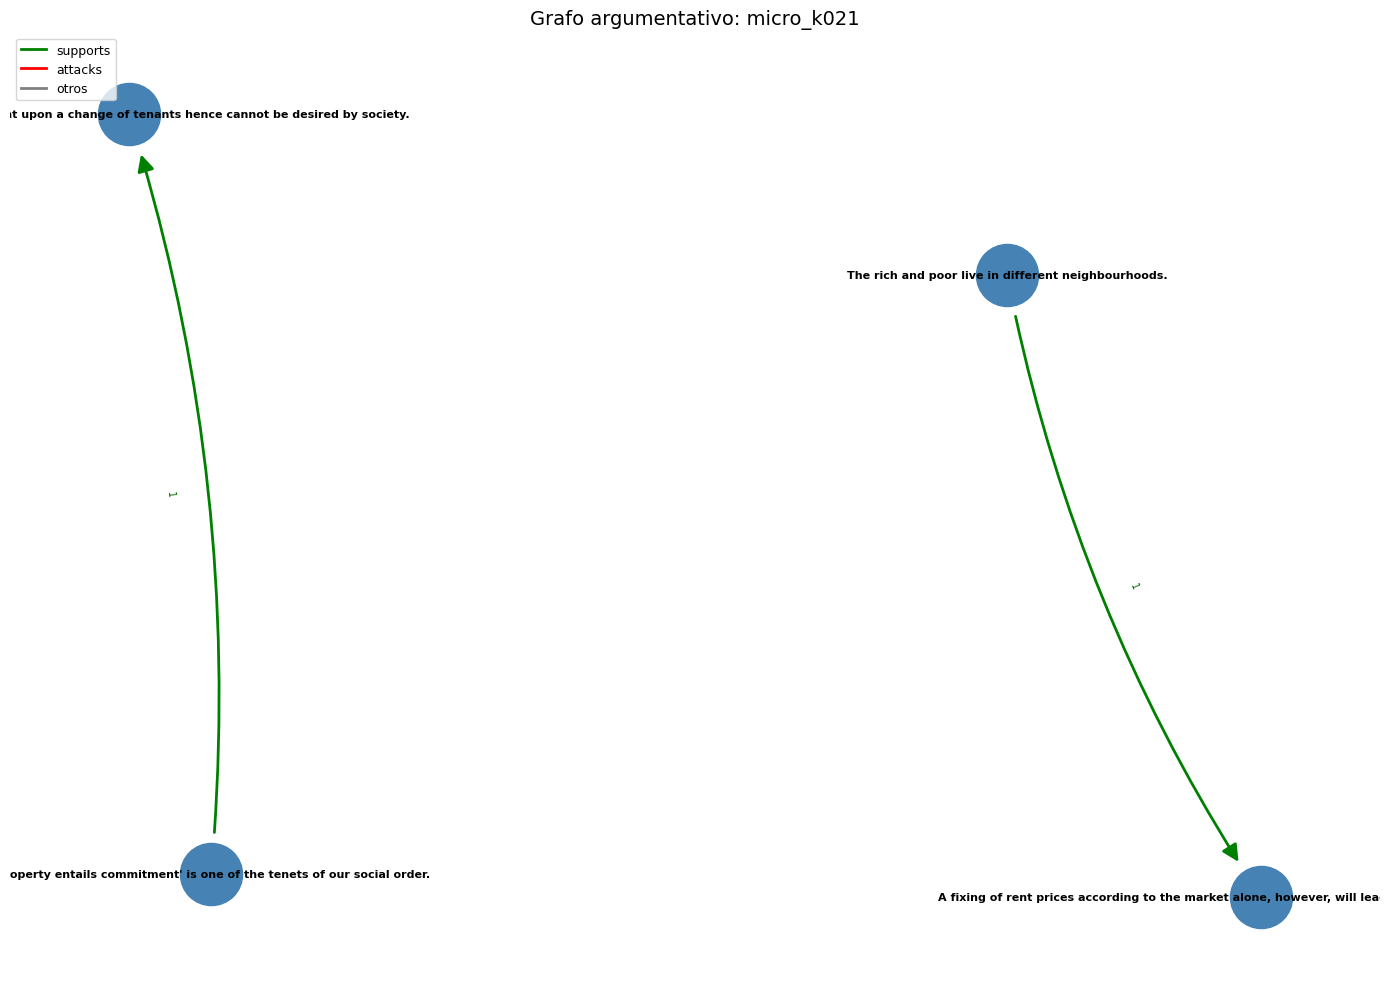

In [84]:
def plot_grafo(microtext_id, df_graph):
    row = df_graph[df_graph["microtext_id"] == microtext_id].iloc[0]
    G   = row["grafo"]
    
    colores_label = {1: "green", 2: "red"}
    edge_colors   = [colores_label.get(d["label"], "gray") for _, _, d in G.edges(data=True)]
    
    plt.figure(figsize=(14, 10))
    pos = nx.spring_layout(G, seed=42, k=0.5, iterations=10)
    
    nx.draw_networkx_nodes(G, pos, node_color="steelblue", node_size=2000)
    nx.draw_networkx_labels(G, pos, font_color="black", font_size=8, font_weight="bold")
    nx.draw_networkx_edges(
        G, pos,
        edge_color=edge_colors,
        arrows=True, arrowsize=25, arrowstyle="-|>",
        width=2, connectionstyle="arc3,rad=0.1",
        min_source_margin=30, min_target_margin=30,
    )
    
    edge_labels = nx.get_edge_attributes(G, "label")
    nx.draw_networkx_edge_labels(G, pos, edge_labels=edge_labels, font_size=7, font_color="darkgreen")
    
    from matplotlib.lines import Line2D
    leyenda = [
        Line2D([0], [0], color="green", linewidth=2, label="supports"),
        Line2D([0], [0], color="red",   linewidth=2, label="attacks"),
        Line2D([0], [0], color="gray",  linewidth=2, label="otros"),
    ]
    plt.legend(handles=leyenda, loc="upper left", fontsize=9)
    plt.title(f"Grafo argumentativo: {microtext_id}", fontsize=14)
    plt.axis("off")
    plt.tight_layout()
    plt.show()

# Uso
plot_grafo("micro_k021", df_graph)